# EDA: Contaminación del aire (PM2.5)
**Programa:** TCS AI Explorer | Nombre:Wilson Vargas Raul Iarley | 
**Pasos:** 1. Cargar → 2. Perfilar → 3. Describir → 4. Visualizar → 5. Documentar

| Elemento | Definición |
|---|---|
| **Pregunta** | ¿Cómo cambió el PM2.5 entre países y años, y cuántos países superan la guía de la OMS (5 µg/m³)? |
| **Métrica** | PM2.5 medio anual (µg/m³) |
| **Dimensión** | País y año |
| **Análisis accionable** | Decidir qué países priorizar para mejorar la calidad del aire |

**Fuente:** Our World in Data (datos de Washington University in St. Louis). https://ourworldindata.org/grapher/outdoor-air-pollution-exposure

## 1. Cargar

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

url = "https://ourworldindata.org/grapher/outdoor-air-pollution-exposure.csv?v=1&csvType=full&useColumnShortNames=false"
df = pd.read_csv(url, storage_options={"User-Agent": "Our World In Data data fetch/1.0"})
df.columns = ["pais", "codigo", "anio", "pm25"]
df.to_csv("contaminacion.csv", index=False)  # copia de los datos
df.head()

,pais,codigo,anio,pm25
0,Afghanistan,AFG,1998,20.7
1,Afghanistan,AFG,1999,23.0
2,Afghanistan,AFG,2000,30.4
3,Afghanistan,AFG,2001,35.0
4,Afghanistan,AFG,2002,33.9


Cada fila es un país en un año, con su PM2.5 medio. 

## 2. Perfilar

In [2]:
df.info()
print("Faltantes:")
print(df.isnull().sum())
print("Duplicados:", df.duplicated().sum())

# Nos quedamos solo con países (sin regiones ni 'Mundo')
paises = df[df["codigo"].notna() & ~df["codigo"].astype(str).str.startswith("OWID")]
print("Países:", paises["pais"].nunique())

<class 'pandas.DataFrame'>
RangeIndex: 6912 entries, 0 to 6911
Data columns (total 4 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   pais    6912 non-null   str    
 1   codigo  6912 non-null   str    
 2   anio    6912 non-null   int64  
 3   pm25    6912 non-null   float64
dtypes: float64(1), int64(1), str(2)
memory usage: 216.1 KB
Faltantes:
pais      0
codigo    0
anio      0
pm25      0
dtype: int64
Duplicados: 0
Países: 241


## 3. Describir

In [3]:
primer_anio = paises["anio"].min()
ultimo_anio = paises["anio"].max()
primero = paises[paises["anio"] == primer_anio]
ultimo = paises[paises["anio"] == ultimo_anio]

print("Promedio", primer_anio, ":", round(primero["pm25"].mean(), 1))
print("Promedio", ultimo_anio, ":", round(ultimo["pm25"].mean(), 1))
print("Países sobre la guía de la OMS en", ultimo_anio, ":", (ultimo["pm25"] > 5).sum(), "de", len(ultimo))

Promedio 1998 : 17.3
Promedio 2024 : 18.3
Países sobre la guía de la OMS en 2024 : 213 de 241


In [4]:
# Tabla: 10 países con más PM2.5 en el último año
ultimo.sort_values("pm25", ascending=False).head(10)[["pais", "pm25"]]

,pais,pm25
5075,Qatar,75.5
566,Bangladesh,65.0
3293,Kuwait,57.3
6479,United Arab Emirates,55.7
4751,Pakistan,53.8
1079,Cameroon,51.5
5480,Saudi Arabia,50.4
4454,Nigeria,50.0
2942,Iraq,48.8
539,Bahrain,48.1


## 4. Visualizar

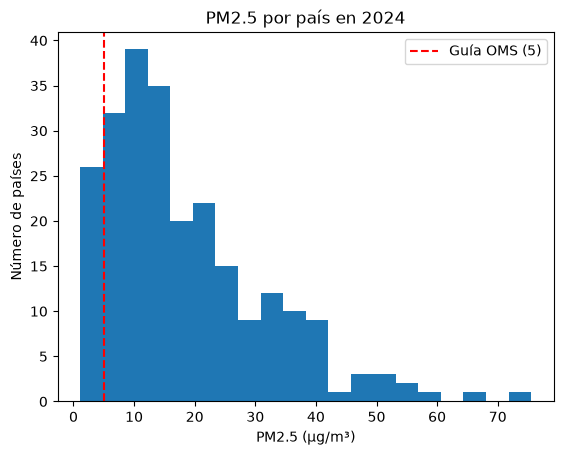

In [5]:
plt.hist(ultimo["pm25"], bins=20)
plt.axvline(5, color="red", linestyle="--", label="Guía OMS (5)")
plt.title("PM2.5 por país en " + str(ultimo_anio))
plt.xlabel("PM2.5 (µg/m³)")
plt.ylabel("Número de países")
plt.legend()
plt.show()

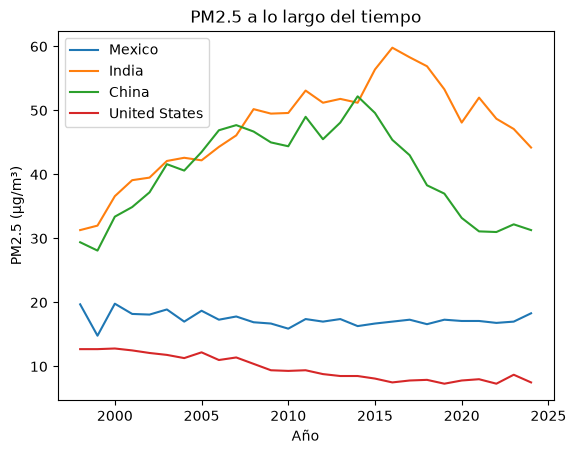

In [6]:
for nombre in ["Mexico", "India", "China", "United States"]:
    datos = paises[paises["pais"] == nombre]
    plt.plot(datos["anio"], datos["pm25"], label=nombre)
plt.title("PM2.5 a lo largo del tiempo")
plt.xlabel("Año")
plt.ylabel("PM2.5 (µg/m³)")
plt.legend()
plt.show()

## 5. Documentar

### Hallazgos
1. *Cuántos países superan la guía de la OMS: *
2. *Qué países tienen más contaminación: Qatar,Bangladesh, Kuwait y UAE*
3. *Cómo cambió México u otro país con los años:Mexico se ha mantenido en el mismo rango durante los ultimos 20 años*


### Límites
- Son estimaciones por satélite, no mediciones de estaciones.
- Es un promedio por país: no muestra diferencias entre ciudades.

### Acción sugerida
*[Qué países priorizarías y por qué: Priorizaria los primeros 4 que son qatar,kuwait,UAE y bangladesh. Recomendaria: Instalar filtros avanzados en refinerías y eliminar por completo la quema de gas en antorchas,
Exigir mallas protectoras, riego constante con agua tratada y cobertura de camiones de carga en los megaproyectos urbanos.
Sacar de circulación autobuses y camiones viejos de diésel altamente contaminantes y ampliar redes de metro y autobuses eléctricos*